# How machines learn: unsupervised learning

[Regression](regression.ipynb) and [classification](classification.ipynb) both learned to predict a target from labeled examples. Unsupervised learning gets no labels and looks for structure in the points themselves. Two classic methods: k-means groups points into clusters, PCA finds the directions the data spreads along.

Both run on the two-cluster dataset from the classification notebook. The labels are kept only to check the results, never to fit.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def make_blobs(n=200, seed=0):
    rng = np.random.default_rng(seed)
    n0, n1 = n // 2, n - n // 2
    class0 = rng.normal(loc=[-1.2, -1.2], scale=1.1, size=(n0, 2))
    class1 = rng.normal(loc=[1.6, 1.6], scale=1.1, size=(n1, 2))
    X = np.vstack([class0, class1])
    y = np.concatenate([np.zeros(n0), np.ones(n1)])
    return X, y

X_cls, y_cls = make_blobs()

## k-Means clustering

Pick `k` starting centroids (cluster centers), then repeat two steps until nothing moves:

1. Assign every point to its nearest centroid.
2. Move each centroid to the mean of the points assigned to it.

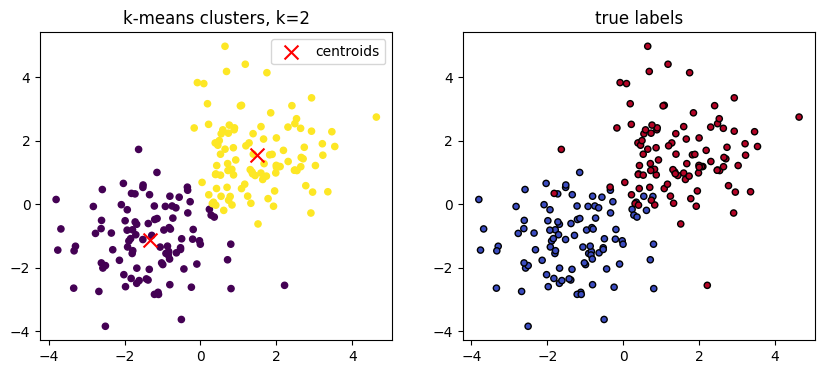

In [2]:
class KMeans:
    def __init__(self, k=3, max_iter=100, seed=0):
        self.k = k
        self.max_iter = max_iter
        self.rng = np.random.default_rng(seed)

    def fit(self, X):
        init = self.rng.choice(len(X), self.k, replace=False)  # start at k random points
        self.centroids_ = X[init].copy()
        for _ in range(self.max_iter):
            # distance from every point to every centroid: shape (n_points, k)
            dists = np.linalg.norm(X[:, None, :] - self.centroids_[None, :, :], axis=2)
            labels = dists.argmin(axis=1)
            new_centroids = np.array([
                X[labels == j].mean(axis=0) if np.any(labels == j) else self.centroids_[j]
                for j in range(self.k)
            ])
            if np.allclose(new_centroids, self.centroids_):
                break
            self.centroids_ = new_centroids
        self.labels_ = labels
        self.inertia_ = ((X - self.centroids_[labels]) ** 2).sum()
        return self

km = KMeans(k=2, seed=0).fit(X_cls)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X_cls[:, 0], X_cls[:, 1], c=km.labels_, cmap="viridis", s=20)
axes[0].scatter(km.centroids_[:, 0], km.centroids_[:, 1], c="red", marker="x", s=100, label="centroids")
axes[0].legend()
axes[0].set_title("k-means clusters, k=2")
axes[1].scatter(X_cls[:, 0], X_cls[:, 1], c=y_cls, cmap="coolwarm", edgecolor="k", s=20)
axes[1].set_title("true labels")
plt.show()

What to look for: without ever seeing a label, k-means recovers almost the same two groups. It disagrees only in the overlap, where it has no information to go on beyond distance. (Which cluster gets which color is arbitrary.)

## Choosing k

`k` has to be chosen up front, and nothing in the algorithm says what it should be. One way to choose: fit for a range of `k` values and plot **inertia**, the total squared distance from each point to its centroid. Inertia always decreases as `k` grows, since more centroids means every point is closer to one. Look for the "elbow" where it stops dropping quickly.

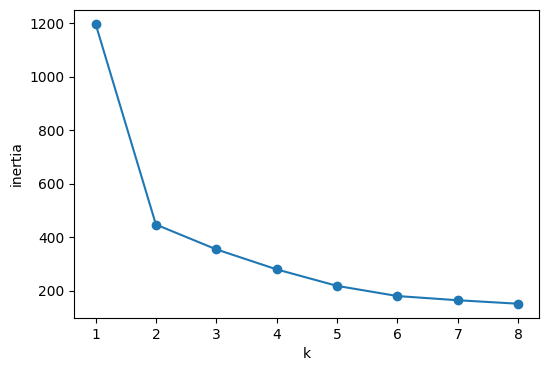

In [3]:
ks = range(1, 9)
inertias = [KMeans(k=k, seed=0).fit(X_cls).inertia_ for k in ks]

plt.figure(figsize=(6, 4))
plt.plot(ks, inertias, marker="o")
plt.xlabel("k")
plt.ylabel("inertia")
plt.show()

What to look for: a big drop from `k=1` to `k=2`, then much smaller drops after. The elbow at 2 matches the two clusters the data was generated from.

## PCA

k-means groups points; PCA finds directions. Center the data (subtract the mean), compute its covariance matrix, and take that matrix's eigenvectors. They point along the axes of greatest spread, sorted by how much spread each one captures. The first one is the single direction that keeps the most information if you squash the data down to one dimension.

variance explained by each component: [0.811 0.189]


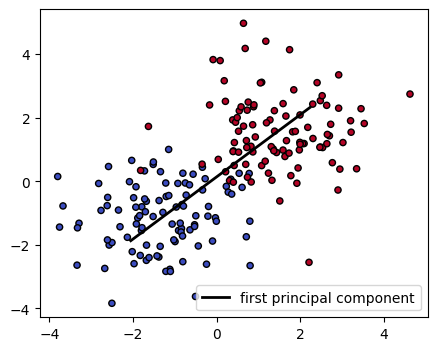

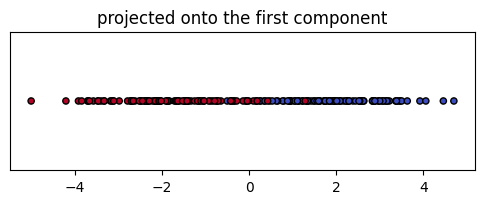

In [4]:
def pca(X):
    X_centered = X - X.mean(axis=0)
    eigvals, eigvecs = np.linalg.eigh(np.cov(X_centered, rowvar=False))
    order = np.argsort(eigvals)[::-1]  # largest spread first
    return eigvals[order], eigvecs[:, order], X_centered

eigvals, eigvecs, X_centered = pca(X_cls)
print("variance explained by each component:", np.round(eigvals / eigvals.sum(), 3))

pc1 = eigvecs[:, 0]
mean = X_cls.mean(axis=0)
span = np.array([mean - 3 * pc1, mean + 3 * pc1])

plt.figure(figsize=(5, 4))
plt.scatter(X_cls[:, 0], X_cls[:, 1], c=y_cls, cmap="coolwarm", edgecolor="k", s=20)
plt.plot(span[:, 0], span[:, 1], color="black", linewidth=2, label="first principal component")
plt.legend()
plt.show()

projected = X_centered @ pc1  # each point's position along the first component
plt.figure(figsize=(6, 1.8))
plt.scatter(projected, np.zeros_like(projected), c=y_cls, cmap="coolwarm", edgecolor="k", s=20)
plt.yticks([])
plt.title("projected onto the first component")
plt.show()

What to look for: the first component runs diagonally from one cluster to the other. Projected onto that single line, the two classes still mostly separate, so one number per point keeps most of what matters.

# Summary

Neither method uses labels. k-means groups points by distance to a set of centers, and the elbow in its inertia curve suggests how many groups there are. PCA finds the directions the data spreads along, which lets you describe it with fewer numbers while keeping most of the information.